# Lab 06: Text Representation and Sentiment Classification

| | |
|---|---|
| **Name** | MUHAMMAD AZLAN |
| **Reg. No.** | SP24-BDS-030 |
| **Lab** | 06 |
| **Dataset** | App store reviews of a travel-planning app (`app_store_reviews.csv`) |
| **Topic** | Bag-of-Words, TF-IDF, Multinomial Naive Bayes, Logistic Regression, sklearn Pipeline |

---

### Contents
1. **Setup and Data Loading** (including how the sentiment label is built)
2. **Activity 1**: Bag-of-Words with `CountVectorizer`
3. **Activity 2**: TF-IDF with `TfidfVectorizer` (raw count vs TF-IDF weight)
4. **Activity 3**: Train/test split and model training
5. **Activity 4**: Evaluation (accuracy, precision, recall, F1, confusion matrices)
6. **Activity 5**: Final `Pipeline` and predictions on new reviews
7. **Conclusion**

## 1. Setup and Data Loading

Keep `app_store_reviews.csv` in the same folder as this notebook (any file name that contains `app_store_reviews` is found automatically). The file is **semicolon-separated**.

In [23]:
import os, re, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.pipeline import Pipeline
from sklearn.base import clone

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 95)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


In [24]:
DATA_PATH = "app_store_reviews.csv"
if not os.path.exists(DATA_PATH):
    matches = glob.glob("*app_store_reviews*.csv")
    if not matches:
        raise FileNotFoundError("Place app_store_reviews.csv in the same folder as this notebook.")
    DATA_PATH = matches[0]

raw = pd.read_csv(DATA_PATH, sep=";")
print("File   :", DATA_PATH)
print("Shape  :", raw.shape)
print("Columns:", list(raw.columns))
raw.head()

File   : app_store_reviews.csv
Shape  : (321, 10)
Columns: ['date', 'platform', 'country', 'review', 'star', 'user_id', 'issue_flag', 'likes_count', 'dislike_count', 'label']


,date,platform,country,review,star,user_id,issue_flag,likes_count,dislike_count,label
0,7.07.2023,iOS,Australia,Love the itinerary sharing feature. It makes planning group trips so much easier!,5,13c95471-be12-42f6-95d1-fa3dd104909b,No,1,1,NaN
1,12.08.2023,Android,India,"The premium price is a bit high, but the features are okay.",4,945725ef-7277-4884-b717-9259af1df8d2,No,2,2,NaN
2,12.09.2023,iOS,UK,"I can't share my trip details via WhatsApp directly, which would be a great feature.",5,e3d956b8-6e00-4099-84ca-f51406e6b3f7,No,5,3,NaN
3,12.07.2023,Android,Brazil,"The price of premium is too high, could be better.",3,1fa559f7-a707-4f23-97f9-1cb92a0ba85b,No,0,0,NaN
4,24.09.2023,iOS,India,Smooth booking experience.,3,67934645-a9bf-4283-b809-1baa3f067b19,No,2,5,NaN


In [25]:
print("Missing values per column:")
print(raw.isna().sum().to_string())
print("\nStar rating distribution:")
print(raw["star"].value_counts().sort_index().to_string())

Missing values per column:
date               0
platform           0
country            0
review             0
star               0
user_id            0
issue_flag         0
likes_count        0
dislike_count      0
label            321

Star rating distribution:
star
1    49
2    78
3    70
4    73
5    51


### Building the sentiment label

The dataset's own `label` column is **completely empty**, so a sentiment target has to be created. The standard approach for review data is to use the star rating:

| Stars | Class |
|---|---|
| 4 or 5 | **positive** (1) |
| 1 or 2 | **negative** (0) |
| 3 | neutral, **removed** (neither clearly positive nor negative) |

Cleaning steps: fix stray spaces before apostrophes (e.g. `aren 't` becomes `aren't`), remove the 3-star reviews, and drop **exact duplicate review texts**. Duplicates matter because the same sentence would otherwise land in both the training and test sets and inflate the scores.

In [26]:
df = raw.dropna(subset=["review", "star"]).copy()

# 1) tidy the text
df["review"] = (df["review"].astype(str)
                .str.replace(r"\s+'(?=\w)", "'", regex=True)   # "aren 't" -> "aren't"
                .str.replace(r"\s+", " ", regex=True)
                .str.strip())

n_start = len(df)

# 2) remove neutral 3-star reviews
df = df[df["star"] != 3]
n_after_neutral = len(df)

# 3) remove exact duplicate review texts (keep the first)
df = df.drop_duplicates(subset="review").reset_index(drop=True)
n_final = len(df)

# 4) sentiment label from stars
df["label"] = (df["star"] >= 4).astype(int)

print(f"Reviews in file            : {n_start}")
print(f"After removing 3-star      : {n_after_neutral}")
print(f"After removing duplicates  : {n_final}")
print("\nClass balance:")
print(df["label"].map({0: "negative (1-2 stars)", 1: "positive (4-5 stars)"}).value_counts().to_string())

X_text = df["review"]
y = df["label"]
df[["review", "star", "label"]].head()

Reviews in file            : 321
After removing 3-star      : 251
After removing duplicates  : 219

Class balance:
label
positive (4-5 stars)    115
negative (1-2 stars)    104


,review,star,label
0,Love the itinerary sharing feature. It makes planning group trips so much easier!,5,1
1,"The premium price is a bit high, but the features are okay.",4,1
2,"I can't share my trip details via WhatsApp directly, which would be a great feature.",5,1
3,Premium access is affordable and totally enhances the app experience.,2,0
4,Not too many ads compared to other apps.,2,0


**A caution about this label.** Star ratings in this dataset do not always agree with what the review says. The cells below list reviews whose text and star rating point in opposite directions. Because the classifier can only learn from the label it is given, this noise will limit how well any model can score.

In [27]:
pos_words = r"love|great|best|perfect|amazing|worth|excellent|fantastic"
neg_words = r"crash|terrible|hate|unbearable|annoying|frustrat|unusable|buggy|freez"

print("Positive-sounding text but LOW stars (1-2):")
print(df[(df["star"] <= 2) & df["review"].str.contains(pos_words, case=False)][["review", "star"]].head(5).to_string(index=False))

print("\nNegative-sounding text but HIGH stars (4-5):")
print(df[(df["star"] >= 4) & df["review"].str.contains(neg_words, case=False)][["review", "star"]].head(5).to_string(index=False))

Positive-sounding text but LOW stars (1-2):
                                                                                 review  star
                                                              Best for travel planning.     2
                         The latest update fixed all the bugs, app works perfectly now!     2
This app is perfect for group trips. Everyone can see the plan and add their own notes.     2
      It's great for organizing travel, but the user interface could be more intuitive.     2
                           Update made the app way better, great job fixing those bugs!     2

Negative-sounding text but HIGH stars (4-5):
                                                                                       review  star
The app constantly needs updates, and it gets frustrating when I'm in the middle of planning.     4
                                              Unskippable ads make the app unbearable to use.     5
              I keep getting logged out at ran

---
## Activity 1: Bag-of-Words with `CountVectorizer`

**Goal:** convert every review into a vector of word counts, check the vocabulary size, and print a readable portion of the sparse document-term matrix.

A Bag-of-Words model ignores grammar and word order and records only **how many times each word occurs** in each review. English stop words are removed so the vocabulary focuses on meaningful terms.

In [28]:
bow_vectorizer = CountVectorizer(stop_words="english", lowercase=True)
X_bow = bow_vectorizer.fit_transform(X_text)

vocab = bow_vectorizer.get_feature_names_out()

print("Document-term matrix type :", type(X_bow).__name__)
print("Matrix shape (docs, terms):", X_bow.shape)
print("Vocabulary size           :", len(vocab))
print("Non-zero entries          :", X_bow.nnz)
print(f"Sparsity                  : {100 * (1 - X_bow.nnz / (X_bow.shape[0] * X_bow.shape[1])):.2f}% zeros")

Document-term matrix type : csr_matrix
Matrix shape (docs, terms): (219, 441)
Vocabulary size           : 441
Non-zero entries          : 1241
Sparsity                  : 98.72% zeros


### Readable view of the sparse matrix
The full matrix is stored sparsely and is too wide to print. A small slice is converted to a dense `DataFrame`: **the first 8 reviews** against **the 12 most frequent words** in the corpus.

In [29]:
total_counts = np.asarray(X_bow.sum(axis=0)).ravel()
top_idx = total_counts.argsort()[::-1][:12]

bow_slice = pd.DataFrame(X_bow[:8, top_idx].toarray(),
                         columns=vocab[top_idx],
                         index=[f"doc_{i}" for i in range(8)])
bow_slice

,app,update,premium,features,great,travel,ads,love,planning,crashes,new,trips
doc_0,0,0,0,0,0,0,0,1,1,0,0,1
doc_1,0,0,1,1,0,0,0,0,0,0,0,0
doc_2,0,0,0,0,1,0,0,0,0,0,0,0
doc_3,1,0,1,0,0,0,0,0,0,0,0,0
doc_4,0,0,0,0,0,0,1,0,0,0,0,0
doc_5,1,0,0,0,0,0,0,0,0,1,1,0
doc_6,0,0,0,0,0,0,0,0,0,0,0,0
doc_7,0,0,0,0,0,0,1,0,0,0,0,0


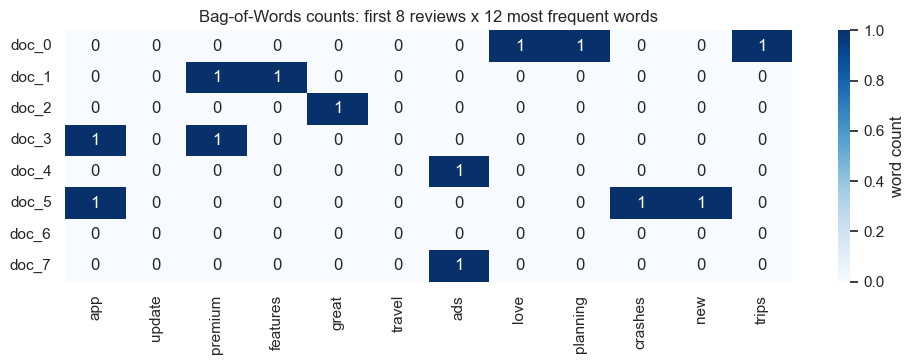

In [30]:
plt.figure(figsize=(10, 3.8))
sns.heatmap(bow_slice, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "word count"})
plt.title("Bag-of-Words counts: first 8 reviews x 12 most frequent words")
plt.tight_layout()
plt.show()

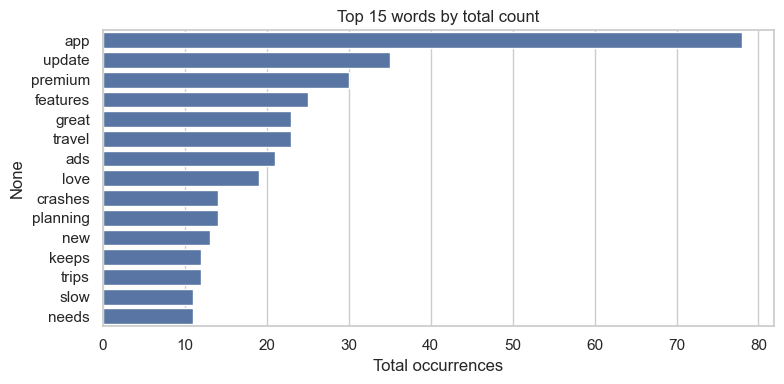

In [31]:
top15 = pd.Series(total_counts, index=vocab).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 4))
sns.barplot(x=top15.values, y=top15.index, color="#4C72B0")
plt.title("Top 15 words by total count")
plt.xlabel("Total occurrences")
plt.tight_layout()
plt.show()

**Observation (Activity 1):** the reviews are short, so most of them contain only a handful of the vocabulary words and the matrix is overwhelmingly zeros. That is why scikit-learn stores it as a **sparse CSR matrix** instead of a full table.

---
## Activity 2: TF-IDF with `TfidfVectorizer`

**Goal:** build a TF-IDF representation and compare the **raw count** weight with the **TF-IDF** weight for two words that appear in many reviews.

$$\text{tf-idf}(t, d) = \text{tf}(t, d) \times \text{idf}(t), \qquad \text{idf}(t) = \ln\frac{1 + n}{1 + \text{df}(t)} + 1$$

Words that appear in many documents get a small IDF, so they are down-weighted. scikit-learn then L2-normalises each row.

In [32]:
tfidf_vectorizer = TfidfVectorizer(stop_words="english", lowercase=True)
X_tfidf = tfidf_vectorizer.fit_transform(X_text)

print("TF-IDF matrix shape:", X_tfidf.shape)
print("Same vocabulary as Bag-of-Words:",
      list(tfidf_vectorizer.get_feature_names_out()) == list(vocab))

TF-IDF matrix shape: (219, 441)
Same vocabulary as Bag-of-Words: True


In [33]:
# Document frequency = number of reviews that contain each word
doc_freq = np.asarray((X_bow > 0).sum(axis=0)).ravel()
df_series = pd.Series(doc_freq, index=vocab).sort_values(ascending=False)

print(f"Most widespread words (out of {X_bow.shape[0]} reviews):")
print(df_series.head(6).to_string())

word_a, word_b = df_series.index[:2]
print(f"\nChosen words: '{word_a}' and '{word_b}'")

Most widespread words (out of 219 reviews):
app         78
update      35
premium     30
features    25
great       23
travel      22

Chosen words: 'app' and 'update'


In [34]:
# Use the first review that contains BOTH words so the comparison is like for like
vocab_index = {w: i for i, w in enumerate(vocab)}
ia, ib = vocab_index[word_a], vocab_index[word_b]
both = np.where((X_bow[:, ia].toarray().ravel() > 0) & (X_bow[:, ib].toarray().ravel() > 0))[0]
doc_id = int(both[0])
print(f"Review #{doc_id}: {X_text[doc_id]}\n")

idf = dict(zip(tfidf_vectorizer.get_feature_names_out(), tfidf_vectorizer.idf_))

comparison = pd.DataFrame({
    "word": [word_a, word_b],
    "reviews containing word": [doc_freq[ia], doc_freq[ib]],
    "IDF": [idf[word_a], idf[word_b]],
    "raw count (BoW)": [X_bow[doc_id, ia], X_bow[doc_id, ib]],
    "TF-IDF weight": [X_tfidf[doc_id, ia], X_tfidf[doc_id, ib]],
}).set_index("word")
comparison.round(4)

Review #12: Not happy with the update, app feels slower and glitchy.



,reviews containing word,IDF,raw count (BoW),TF-IDF weight
word,,,,
app,78,2.0242,1,0.1970
update,35,2.8101,1,0.2735


The final TF-IDF weight comes from two steps: **(1)** count x IDF, then **(2)** L2 normalisation of the whole review vector. Switching normalisation off (`norm=None`) separates the two effects.

In [35]:
unnormalised = TfidfVectorizer(stop_words="english", norm=None).fit_transform(X_text)

steps = pd.DataFrame({
    "raw count": [X_bow[doc_id, ia], X_bow[doc_id, ib]],
    "count x IDF (before normalising)": [unnormalised[doc_id, ia], unnormalised[doc_id, ib]],
    "final TF-IDF (after L2 normalising)": [X_tfidf[doc_id, ia], X_tfidf[doc_id, ib]],
}, index=[word_a, word_b])
steps.round(4)

,raw count,count x IDF (before normalising),final TF-IDF (after L2 normalising)
app,1,2.0242,0.1970
update,1,2.8101,0.2735


In [36]:
# Average weight over every review that actually contains the word
rows = []
for w, i in [(word_a, ia), (word_b, ib)]:
    present = X_bow[:, i].toarray().ravel() > 0
    rows.append({"word": w,
                 "mean raw count (where present)": X_bow[present, i].mean(),
                 "mean TF-IDF (where present)": X_tfidf[present, i].mean()})
pd.DataFrame(rows).set_index("word").round(4)

,mean raw count (where present),mean TF-IDF (where present)
word,,
app,1.0,0.1912
update,1.0,0.2550


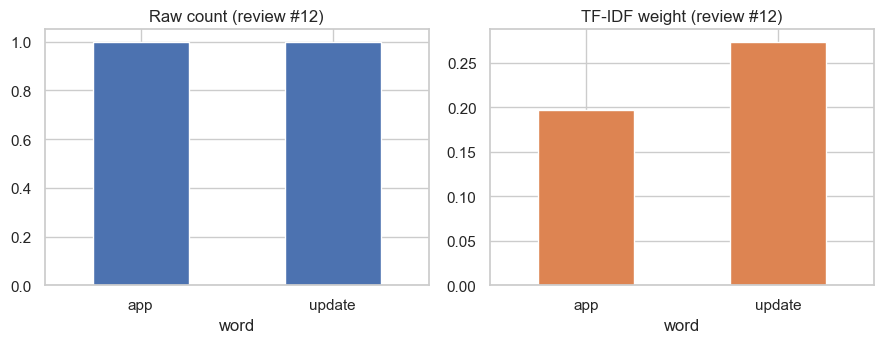

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
comparison["raw count (BoW)"].plot.bar(ax=axes[0], color="#4C72B0", rot=0)
axes[0].set_title(f"Raw count (review #{doc_id})")
comparison["TF-IDF weight"].plot.bar(ax=axes[1], color="#DD8452", rot=0)
axes[1].set_title(f"TF-IDF weight (review #{doc_id})")
plt.tight_layout()
plt.show()

**Why is the TF-IDF weight lower? (one line)**
> "app" and "update" appear in many reviews, so IDF gives them only a small boost, and L2 normalisation then scales the whole review vector down, leaving each weight at a fraction (about 0.2) of its raw count of 1; the more widespread word, "app", ends up lower than "update".

---
## Activity 3: Train/Test Split and Model Training

**Goal:** split the data, train **Multinomial Naive Bayes** and **Logistic Regression** on TF-IDF features, and generate test-set predictions.

To avoid **data leakage**, the TF-IDF vectorizer is **fitted on the training reviews only** and then used to transform the test reviews. A stratified 75/25 split keeps the class balance equal in both sets. The dataset is small, so a quarter is held out to give the test set a reasonable size.

In [38]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

print(f"Train size: {len(X_train_text)}   Test size: {len(X_test_text)}")
print("Train class balance:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test  class balance:", y_test.value_counts(normalize=True).round(3).to_dict())

Train size: 164   Test size: 55
Train class balance: {1: 0.524, 0: 0.476}
Test  class balance: {1: 0.527, 0: 0.473}


In [39]:
tfidf = TfidfVectorizer(stop_words="english", lowercase=True)
X_train = tfidf.fit_transform(X_train_text)      # learn vocabulary + IDF from train only
X_test = tfidf.transform(X_test_text)

print("Train features:", X_train.shape)
print("Test features :", X_test.shape)

Train features: (164, 370)
Test features : (55, 370)


In [40]:
# Model 1: Multinomial Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

# Model 2: Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

print("Both models trained.\n")
names = {0: "negative", 1: "positive"}
pd.DataFrame({
    "review": X_test_text.values,
    "actual": y_test.map(names).values,
    "NB prediction": pd.Series(y_pred_nb).map(names).values,
    "LR prediction": pd.Series(y_pred_lr).map(names).values,
}).head(10)

Both models trained.



,review,actual,NB prediction,LR prediction
0,"The booking confirmation took too long to appear, and I had to restart the app twice.",positive,positive,positive
1,"Notifications are great, but I wish I could customize them more.",positive,positive,positive
2,"The premium version is priced well, great value for frequent travelers.",positive,positive,positive
3,"The UI could be a bit more intuitive, but overall it's a solid app for frequent travelers.",negative,negative,negative
4,"The interface is sleek, but it can get laggy, especially when switching between tabs.",negative,negative,negative
5,Useful but crashes randomly.,negative,negative,negative
6,"Great update, especially loving the new layout and design changes.",positive,negative,negative
7,Keeps all my travel documents in one place. No more lost tickets or confirmation emails.,negative,negative,negative
8,"Update brought more bugs, app crashes at random times now.",negative,negative,negative
9,Quick access to itineraries.,negative,positive,negative


---
## Activity 4: Model Evaluation

**Goal:** evaluate both models on the test set using **accuracy, precision, recall, F1** and display each **confusion matrix**.

- **Accuracy**: share of all predictions that are correct.
- **Precision**: of the reviews predicted *positive*, how many really are.
- **Recall**: of the truly *positive* reviews, how many were found.
- **F1**: harmonic mean of precision and recall.

The positive class (label `1`) is the class of interest.

In [41]:
def evaluate(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 score": f1_score(y_true, y_pred, zero_division=0),
    }

results = pd.DataFrame([
    evaluate("Multinomial Naive Bayes", y_test, y_pred_nb),
    evaluate("Logistic Regression", y_test, y_pred_lr),
]).set_index("Model")

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Majority-class baseline accuracy (always guess the commonest class): "
      f"{accuracy_score(y_test, baseline.predict(X_test)):.4f}\n")
results.round(4)

Majority-class baseline accuracy (always guess the commonest class): 0.5273



,Accuracy,Precision,Recall,F1 score
Model,,,,
Multinomial Naive Bayes,0.6727,0.6897,0.6897,0.6897
Logistic Regression,0.6364,0.6800,0.5862,0.6296


In [42]:
target_names = ["negative", "positive"]
for name, pred in [("Multinomial Naive Bayes", y_pred_nb), ("Logistic Regression", y_pred_lr)]:
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, pred, target_names=target_names, digits=4, zero_division=0))

Multinomial Naive Bayes
              precision    recall  f1-score   support

    negative     0.6538    0.6538    0.6538        26
    positive     0.6897    0.6897    0.6897        29

    accuracy                         0.6727        55
   macro avg     0.6718    0.6718    0.6718        55
weighted avg     0.6727    0.6727    0.6727        55

Logistic Regression
              precision    recall  f1-score   support

    negative     0.6000    0.6923    0.6429        26
    positive     0.6800    0.5862    0.6296        29

    accuracy                         0.6364        55
   macro avg     0.6400    0.6393    0.6362        55
weighted avg     0.6422    0.6364    0.6359        55



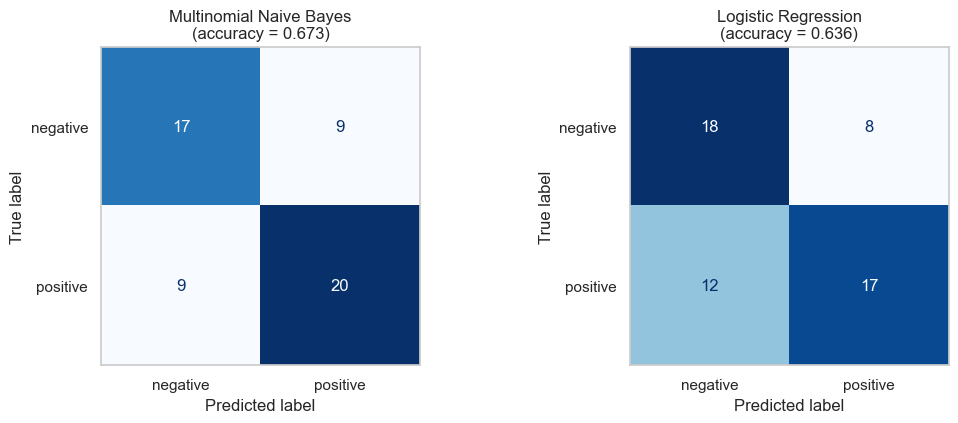

Naive Bayes          TN=17  FP=9  FN=9  TP=20
Logistic Regression  TN=18  FP=8  FN=12  TP=17


In [43]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (name, pred) in zip(axes, [("Multinomial Naive Bayes", y_pred_nb),
                                   ("Logistic Regression", y_pred_lr)]):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=target_names).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}\n(accuracy = {accuracy_score(y_test, pred):.3f})")
    ax.grid(False)
plt.tight_layout()
plt.show()

for name, pred in [("Naive Bayes", y_pred_nb), ("Logistic Regression", y_pred_lr)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    print(f"{name:20s} TN={tn}  FP={fp}  FN={fn}  TP={tp}")

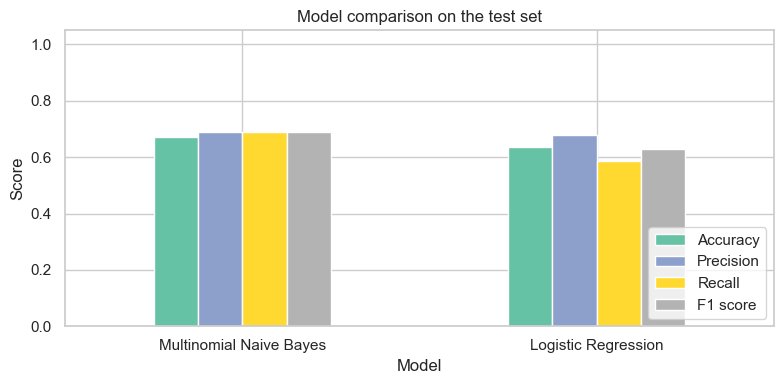

Better-performing model (highest F1): Multinomial Naive Bayes
F1 = 0.6897,  accuracy = 0.6727


In [44]:
results.plot(kind="bar", figsize=(8, 4), rot=0, colormap="Set2")
plt.ylim(0, 1.05)
plt.title("Model comparison on the test set")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_name = results["F1 score"].idxmax()
print(f"Better-performing model (highest F1): {best_name}")
print(f"F1 = {results.loc[best_name, 'F1 score']:.4f},  accuracy = {results.loc[best_name, 'Accuracy']:.4f}")

### Robustness check: cross-validation
The test set is small, so one split can be lucky or unlucky. As a sanity check, each model is also scored with **5-fold stratified cross-validation** on all the data (the vectorizer is refitted inside every fold through a `Pipeline`, so there is no leakage).

In [45]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, clf in [("Multinomial Naive Bayes", MultinomialNB()),
                  ("Logistic Regression", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
                  ("Majority-class baseline", DummyClassifier(strategy="most_frequent"))]:
    pipe = Pipeline([("tfidf", TfidfVectorizer(stop_words="english")), ("clf", clf)])
    acc = cross_val_score(pipe, X_text, y, cv=cv, scoring="accuracy")
    f1 = cross_val_score(pipe, X_text, y, cv=cv, scoring="f1")
    cv_rows.append({"Model": name, "CV accuracy (mean)": acc.mean(), "CV accuracy (std)": acc.std(),
                    "CV F1 (mean)": f1.mean()})
pd.DataFrame(cv_rows).set_index("Model").round(4)

,CV accuracy (mean),CV accuracy (std),CV F1 (mean)
Model,,,
Multinomial Naive Bayes,0.5890,0.0611,0.6473
Logistic Regression,0.5847,0.0422,0.6448
Majority-class baseline,0.5252,0.0049,0.6886


**Observation (Activity 4):** the two models are compared on identical test data, and the one with the higher F1 score is carried into Activity 5 automatically. Accuracy is only modestly above the majority-class baseline, and the cross-validation scores show a similar picture. (The baseline's F1 looks high only because always guessing "positive" gives perfect recall on that class; its accuracy shows it learns nothing.) This is expected here: the sentiment label comes from star ratings, and as shown earlier many reviews have stars that contradict their wording ("Best for travel planning." with 2 stars, "Unskippable ads make the app unbearable to use." with 5 stars). A model cannot learn a pattern that the labels themselves do not follow consistently, so the small gap between models should not be over-interpreted.

---
## Activity 5: Final `Pipeline` and Predictions on New Reviews

**Goal:** bundle the TF-IDF vectorizer and the better classifier from Activity 4 into one `Pipeline`, then classify three brand-new reviews that are not in the dataset.

A pipeline accepts **raw text** and handles vectorizing and classifying in one call, which makes the model easy to save and reuse.

In [46]:
best_classifier = nb_model if best_name == "Multinomial Naive Bayes" else lr_model

final_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", lowercase=True)),
    ("clf", clone(best_classifier)),     # same hyper-parameters as the winning model
])

final_pipeline.fit(X_train_text, y_train)

pipe_pred = final_pipeline.predict(X_test_text)
print("Classifier inside the pipeline:", type(final_pipeline.named_steps["clf"]).__name__)
print(f"Pipeline test accuracy : {accuracy_score(y_test, pipe_pred):.4f}")
print(f"Pipeline test F1 score : {f1_score(y_test, pipe_pred):.4f}")
final_pipeline

Classifier inside the pipeline: MultinomialNB
Pipeline test accuracy : 0.6727
Pipeline test F1 score : 0.6897


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


In [47]:
new_reviews = [
    "Absolutely love this app! Planning group trips is so easy and the premium features are worth every penny.",
    "Terrible experience. The app crashes every time I open it and the ads are unbearable.",
    "The itinerary feature is great, but the app keeps freezing after the latest update.",
]

pred_labels = final_pipeline.predict(new_reviews)
pred_proba = final_pipeline.predict_proba(new_reviews)

label_names = {0: "NEGATIVE", 1: "POSITIVE"}
for i, (text, lab, proba) in enumerate(zip(new_reviews, pred_labels, pred_proba), start=1):
    print(f"Review {i}: {text}")
    print(f"   -> Prediction: {label_names[lab]}   "
          f"(P(negative) = {proba[0]:.3f}, P(positive) = {proba[1]:.3f})\n")

Review 1: Absolutely love this app! Planning group trips is so easy and the premium features are worth every penny.
   -> Prediction: POSITIVE   (P(negative) = 0.212, P(positive) = 0.788)

Review 2: Terrible experience. The app crashes every time I open it and the ads are unbearable.
   -> Prediction: NEGATIVE   (P(negative) = 0.636, P(positive) = 0.364)

Review 3: The itinerary feature is great, but the app keeps freezing after the latest update.
   -> Prediction: NEGATIVE   (P(negative) = 0.548, P(positive) = 0.452)



In [48]:
pd.DataFrame({
    "new review": [t[:62] + "..." for t in new_reviews],
    "prediction": [label_names[l] for l in pred_labels],
    "P(negative)": pred_proba[:, 0].round(3),
    "P(positive)": pred_proba[:, 1].round(3),
})

,new review,prediction,P(negative),P(positive)
0,Absolutely love this app! Planning group trips is so easy and ...,POSITIVE,0.212,0.788
1,Terrible experience. The app crashes every time I open it and ...,NEGATIVE,0.636,0.364
2,"The itinerary feature is great, but the app keeps freezing aft...",NEGATIVE,0.548,0.452


**Observation (Activity 5):** the pipeline accepts raw sentences and returns a sentiment plus class probabilities with no manual preprocessing. The clearly positive review is classified positive and the clearly negative one negative. The third review is deliberately mixed ("great" feature but the app "keeps freezing"); the model leans negative but with probabilities close to 50/50, which shows a bag-of-words model cannot weigh a "but" clause the way a reader does. All probabilities are moderate because the training set is small (about 160 reviews) and its star-based labels are noisy, so these predictions are a demonstration of the pipeline rather than a reliable sentiment tool.

---
## Conclusion

| Activity | What was done | Key takeaway |
|---|---|---|
| 1 | Bag-of-Words (`CountVectorizer`) | Short reviews give a very sparse matrix |
| 2 | TF-IDF (`TfidfVectorizer`) | Words found in many reviews are down-weighted because their IDF is low |
| 3 | 75/25 stratified split, NB and Logistic Regression | Vectorizer fitted on train only, so there is no leakage |
| 4 | Accuracy, precision, recall, F1, confusion matrices, cross-validation | The best model was chosen by F1; scores are limited by noisy star-based labels |
| 5 | `Pipeline(TF-IDF + best classifier)` | Raw text in, sentiment and probability out |

**Data note:** the dataset's `label` column was empty, so sentiment was derived from star ratings (4-5 positive, 1-2 negative, 3 removed). Where stars and wording disagree, model scores are naturally capped.

**Submitted by:** MUHAMMAD AZLAN  |  **Reg. No.:** SP24-BDS-030